# General

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

In [3]:
x_train = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0
print('Training:', x_train.shape, 'Test:', x_test.shape)

Training: (60000, 28, 28) Test: (10000, 28, 28)


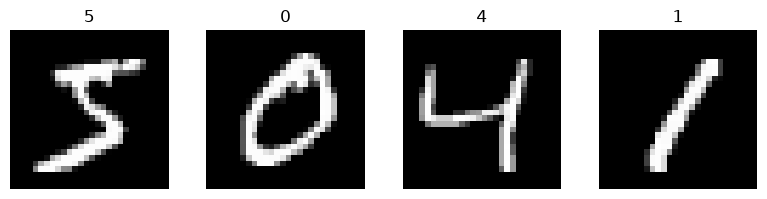

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(8, 2))
for i, ax in enumerate(axs):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
train_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.1, random_state=42, stratify=y_train
)
print('Training:', len(train_idx), 'Validation:', len(val_idx), 'Test:', len(y_test))

Training: 54000 Validation: 6000 Test: 10000


In [6]:
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Models

In [7]:
def build_model(name):
    model = keras.Sequential([layers.Input(shape=(28, 28, 1))])
    if name == 'simple':
        model.add(layers.Conv2D(32, 5, activation='relu'))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Dropout(0.2))
        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
    elif name == 'complex':
        model.add(layers.Conv2D(30, 5, activation='relu'))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Conv2D(15, 3, activation='relu'))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Dropout(0.2))
        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dense(50, activation='relu'))
    else:
        for units in [32, 64]:
            model.add(layers.Conv2D(units, 3, padding='same', activation='relu'))
            if name == 'deeper':
                model.add(layers.Conv2D(units, 3, padding='same', activation='relu'))
            model.add(layers.MaxPooling2D(2))
            model.add(layers.Dropout(0.2))
        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Training

In [9]:
def plot_history(history, name):
    history = pd.DataFrame(history)
    epochs = np.arange(1, len(history) + 1)

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axs, ['accuracy', 'loss']):
        ax.plot(epochs, history[metric], label='Training')
        if f'val_{metric}' in history:
            ax.plot(epochs, history[f'val_{metric}'], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

Compare the four models on the same validation split. Keep the checkpoint with the lowest validation loss.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,074 (2.26 MB)

 Trainable params: 592,074 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
270/270 - 6s - 23ms/step - accuracy: 0.9313 - loss: 0.2422 - val_accuracy: 0.9745 - val_loss: 0.0937
Epoch 2/10
270/270 - 1s - 5ms/step - accuracy: 0.9769 - loss: 0.0759 - val_accuracy: 0.9808 - val_loss: 0.0674
Epoch 3/10
270/270 - 1s - 5ms/step - accuracy: 0.9838 - loss: 0.0530 - val_accuracy: 0.9828 - val_loss: 0.0662
Epoch 4/10
270/270 - 1s - 5ms/step - accuracy: 0.9868 - loss: 0.0423 - val_accuracy: 0.9843 - val_loss: 0.0567
Epoch 5/10
270/270 - 1s - 4ms/step - accuracy: 0.9897 - loss: 0.0334 - val_accuracy: 0.9850 - val_loss: 0.0530
Epoch 6/10
270/270 - 1s - 5ms/step - accuracy: 0.9913 - loss: 0.0276 - val_accuracy: 0.9862 - val_loss: 0.0528
Epoch 7/10
270/270 - 1s - 4ms/step - accuracy: 0.9926 - loss: 0.0235 - val_accuracy: 0.9865 - val_loss: 0.0532
Epoch 8/10
270/270 - 1s - 5ms/step - accuracy: 0.9936 - loss: 0.0196 - val_accuracy: 0.9860 - val_loss: 0.0519
Epoch 9/10
270/270 - 1s - 5ms/step - accuracy: 0.9946 - loss: 0.0164 - val_accuracy: 0.9870 - val_loss: 0.0553


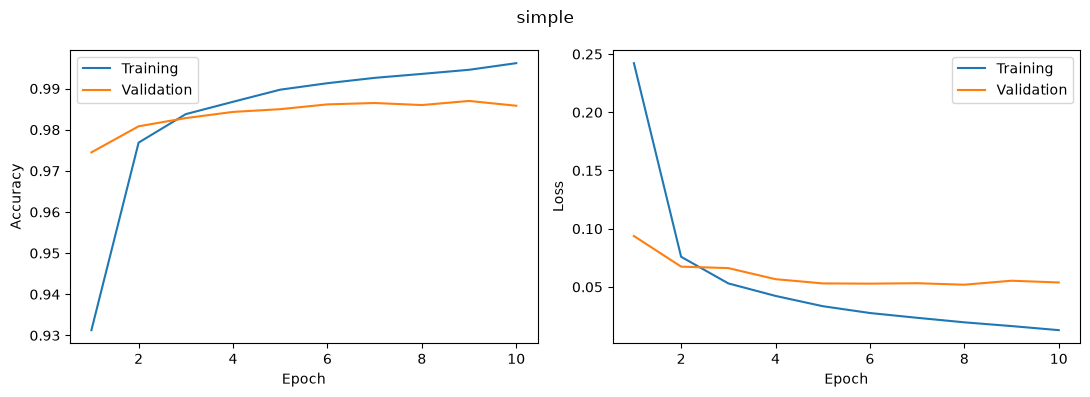

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 30)     │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 15)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 5, 15)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 375)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        48,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         6,450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,933 (234.11 KB)

 Trainable params: 59,933 (234.11 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
270/270 - 6s - 23ms/step - accuracy: 0.8695 - loss: 0.4137 - val_accuracy: 0.9693 - val_loss: 0.1101
Epoch 2/10
270/270 - 1s - 4ms/step - accuracy: 0.9683 - loss: 0.1047 - val_accuracy: 0.9793 - val_loss: 0.0711
Epoch 3/10
270/270 - 1s - 4ms/step - accuracy: 0.9764 - loss: 0.0753 - val_accuracy: 0.9847 - val_loss: 0.0590
Epoch 4/10
270/270 - 1s - 4ms/step - accuracy: 0.9815 - loss: 0.0599 - val_accuracy: 0.9865 - val_loss: 0.0501
Epoch 5/10
270/270 - 1s - 4ms/step - accuracy: 0.9838 - loss: 0.0515 - val_accuracy: 0.9863 - val_loss: 0.0494
Epoch 6/10
270/270 - 1s - 4ms/step - accuracy: 0.9864 - loss: 0.0430 - val_accuracy: 0.9875 - val_loss: 0.0461
Epoch 7/10
270/270 - 1s - 4ms/step - accuracy: 0.9878 - loss: 0.0394 - val_accuracy: 0.9890 - val_loss: 0.0455
Epoch 8/10
270/270 - 1s - 4ms/step - accuracy: 0.9888 - loss: 0.0359 - val_accuracy: 0.9895 - val_loss: 0.0407
Epoch 9/10
270/270 - 1s - 4ms/step - accuracy: 0.9894 - loss: 0.0334 - val_accuracy: 0.9880 - val_loss: 0.0412


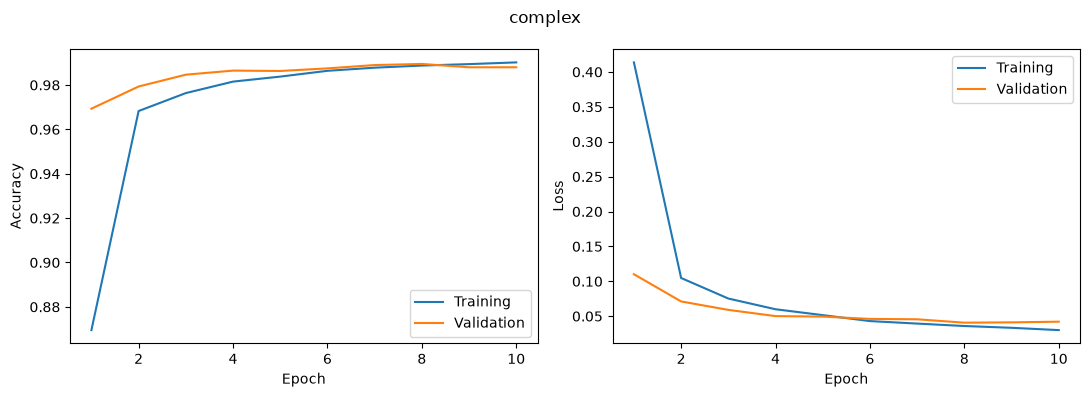

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
270/270 - 8s - 29ms/step - accuracy: 0.8967 - loss: 0.3332 - val_accuracy: 0.9737 - val_loss: 0.0887
Epoch 2/10
270/270 - 2s - 7ms/step - accuracy: 0.9691 - loss: 0.1006 - val_accuracy: 0.9828 - val_loss: 0.0581
Epoch 3/10
270/270 - 2s - 7ms/step - accuracy: 0.9776 - loss: 0.0722 - val_accuracy: 0.9858 - val_loss: 0.0496
Epoch 4/10
270/270 - 2s - 7ms/step - accuracy: 0.9824 - loss: 0.0581 - val_accuracy: 0.9857 - val_loss: 0.0469
Epoch 5/10
270/270 - 2s - 7ms/step - accuracy: 0.9853 - loss: 0.0477 - val_accuracy: 0.9870 - val_loss: 0.0442
Epoch 6/10
270/270 - 2s - 7ms/step - accuracy: 0.9867 - loss: 0.0428 - val_accuracy: 0.9897 - val_loss: 0.0382
Epoch 7/10
270/270 - 2s - 7ms/step - accuracy: 0.9877 - loss: 0.0384 - val_accuracy: 0.9892 - val_loss: 0.0378
Epoch 8/10
270/270 - 2s - 7ms/step - accuracy: 0.9890 - loss: 0.0344 - val_accuracy: 0.9903 - val_loss: 0.0371
Epoch 9/10
270/270 - 2s - 7ms/step - accuracy: 0.9901 - loss: 0.0302 - val_accuracy: 0.9902 - val_loss: 0.0393


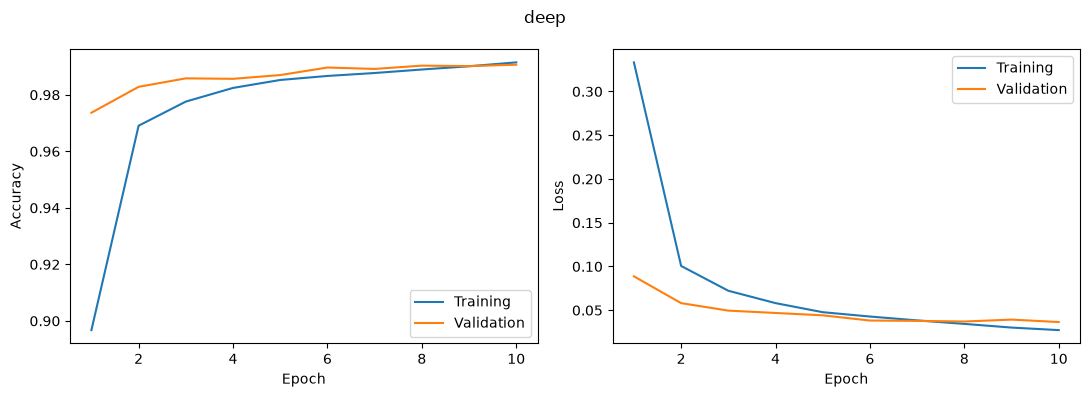

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
270/270 - 10s - 37ms/step - accuracy: 0.9121 - loss: 0.2815 - val_accuracy: 0.9792 - val_loss: 0.0746
Epoch 2/10
270/270 - 4s - 15ms/step - accuracy: 0.9761 - loss: 0.0794 - val_accuracy: 0.9868 - val_loss: 0.0533
Epoch 3/10
270/270 - 4s - 15ms/step - accuracy: 0.9828 - loss: 0.0558 - val_accuracy: 0.9865 - val_loss: 0.0441
Epoch 4/10
270/270 - 4s - 15ms/step - accuracy: 0.9861 - loss: 0.0448 - val_accuracy: 0.9897 - val_loss: 0.0351
Epoch 5/10
270/270 - 4s - 15ms/step - accuracy: 0.9884 - loss: 0.0366 - val_accuracy: 0.9890 - val_loss: 0.0357
Epoch 6/10
270/270 - 4s - 15ms/step - accuracy: 0.9907 - loss: 0.0294 - val_accuracy: 0.9902 - val_loss: 0.0338
Epoch 7/10
270/270 - 4s - 15ms/step - accuracy: 0.9913 - loss: 0.0278 - val_accuracy: 0.9900 - val_loss: 0.0323
Epoch 8/10
270/270 - 4s - 15ms/step - accuracy: 0.9922 - loss: 0.0235 - val_accuracy: 0.9895 - val_loss: 0.0356
Epoch 9/10
270/270 - 4s - 15ms/step - accuracy: 0.9931 - loss: 0.0219 - val_accuracy: 0.9902 - val_loss

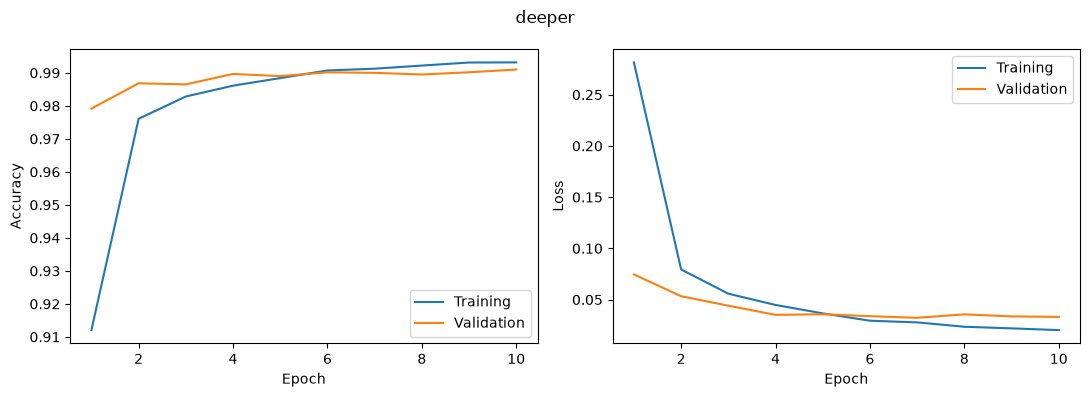

In [10]:
results = []
for name in ['simple', 'complex', 'deep', 'deeper']:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    model = build_model(name)
    model.summary()
    hist = model.fit(
        x_train[train_idx], y_train_cat[train_idx],
        validation_data=(x_train[val_idx], y_train_cat[val_idx]),
        epochs=10, batch_size=200, verbose=2,
        callbacks=[
            keras.callbacks.ModelCheckpoint(f'models/{name}.keras', monitor='val_loss', save_best_only=True),
        ]
    )
    model = keras.models.load_model(f'models/{name}.keras')
    train_loss, train_accuracy = model.evaluate(x_train[train_idx], y_train_cat[train_idx], verbose=0)
    val_loss, val_accuracy = model.evaluate(x_train[val_idx], y_train_cat[val_idx], verbose=0)
    results.append({
        'name': name,
        'parameters': model.count_params(),
        'train_loss': train_loss,
        'train_accuracy': train_accuracy,
        'val_loss': val_loss,
        'val_accuracy': val_accuracy,
        'best_epoch': int(np.argmin(hist.history['val_loss']) + 1)
    })
    plot_history(hist.history, name)

In [11]:
results = pd.DataFrame(results)
results

,name,parameters,train_loss,train_accuracy,val_loss,val_accuracy,best_epoch
0,simple,592074,0.009267,0.997611,0.051892,0.986000,8
1,complex,59933,0.018146,0.994370,0.040701,0.989500,8
2,deep,421642,0.008682,0.997648,0.036496,0.990667,10
3,deeper,467818,0.009649,0.997111,0.032255,0.990000,7


# Cross-validation

Run five folds for `deep` and `deeper`, starting with fresh weights in each fold.

Epoch 1/10
240/240 - 6s - 24ms/step - accuracy: 0.8944 - loss: 0.3450 - val_accuracy: 0.9704 - val_loss: 0.0956
Epoch 2/10
240/240 - 2s - 7ms/step - accuracy: 0.9702 - loss: 0.0993 - val_accuracy: 0.9812 - val_loss: 0.0624
Epoch 3/10
240/240 - 2s - 7ms/step - accuracy: 0.9778 - loss: 0.0715 - val_accuracy: 0.9849 - val_loss: 0.0486
Epoch 4/10
240/240 - 2s - 7ms/step - accuracy: 0.9816 - loss: 0.0582 - val_accuracy: 0.9868 - val_loss: 0.0423
Epoch 5/10
240/240 - 2s - 7ms/step - accuracy: 0.9846 - loss: 0.0484 - val_accuracy: 0.9889 - val_loss: 0.0380
Epoch 6/10
240/240 - 2s - 7ms/step - accuracy: 0.9865 - loss: 0.0431 - val_accuracy: 0.9880 - val_loss: 0.0406
Epoch 7/10
240/240 - 2s - 7ms/step - accuracy: 0.9880 - loss: 0.0367 - val_accuracy: 0.9881 - val_loss: 0.0402
Epoch 8/10
240/240 - 2s - 7ms/step - accuracy: 0.9894 - loss: 0.0333 - val_accuracy: 0.9899 - val_loss: 0.0360
Epoch 9/10
240/240 - 2s - 7ms/step - accuracy: 0.9905 - loss: 0.0299 - val_accuracy: 0.9906 - val_loss: 0.0356


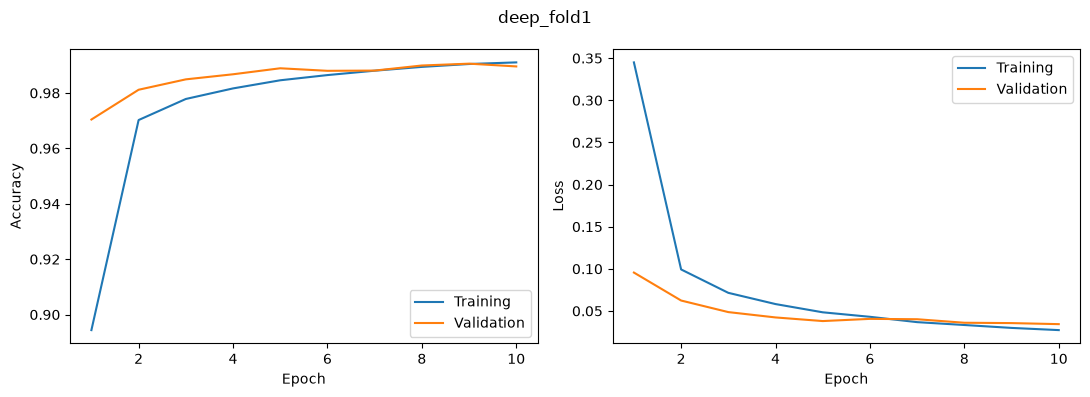

Epoch 1/10
240/240 - 6s - 23ms/step - accuracy: 0.8890 - loss: 0.3662 - val_accuracy: 0.9738 - val_loss: 0.0855
Epoch 2/10
240/240 - 2s - 7ms/step - accuracy: 0.9695 - loss: 0.1010 - val_accuracy: 0.9826 - val_loss: 0.0567
Epoch 3/10
240/240 - 2s - 7ms/step - accuracy: 0.9769 - loss: 0.0744 - val_accuracy: 0.9872 - val_loss: 0.0432
Epoch 4/10
240/240 - 2s - 7ms/step - accuracy: 0.9821 - loss: 0.0572 - val_accuracy: 0.9886 - val_loss: 0.0396
Epoch 5/10
240/240 - 2s - 7ms/step - accuracy: 0.9848 - loss: 0.0501 - val_accuracy: 0.9890 - val_loss: 0.0364
Epoch 6/10
240/240 - 2s - 7ms/step - accuracy: 0.9870 - loss: 0.0409 - val_accuracy: 0.9894 - val_loss: 0.0346
Epoch 7/10
240/240 - 2s - 7ms/step - accuracy: 0.9881 - loss: 0.0377 - val_accuracy: 0.9903 - val_loss: 0.0323
Epoch 8/10
240/240 - 2s - 7ms/step - accuracy: 0.9891 - loss: 0.0334 - val_accuracy: 0.9902 - val_loss: 0.0339
Epoch 9/10
240/240 - 2s - 7ms/step - accuracy: 0.9902 - loss: 0.0309 - val_accuracy: 0.9913 - val_loss: 0.0305


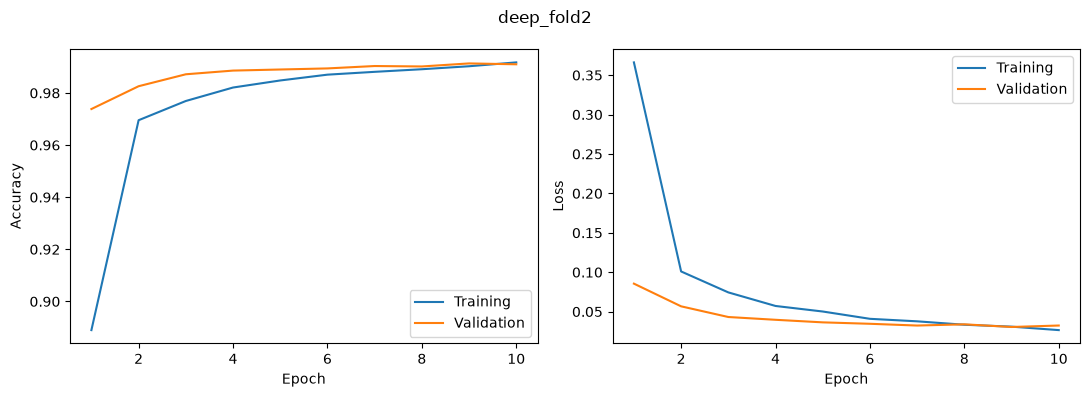

Epoch 1/10
240/240 - 6s - 23ms/step - accuracy: 0.8894 - loss: 0.3595 - val_accuracy: 0.9728 - val_loss: 0.0893
Epoch 2/10
240/240 - 2s - 7ms/step - accuracy: 0.9678 - loss: 0.1053 - val_accuracy: 0.9819 - val_loss: 0.0569
Epoch 3/10
240/240 - 2s - 7ms/step - accuracy: 0.9774 - loss: 0.0746 - val_accuracy: 0.9849 - val_loss: 0.0488
Epoch 4/10
240/240 - 2s - 7ms/step - accuracy: 0.9806 - loss: 0.0617 - val_accuracy: 0.9876 - val_loss: 0.0410
Epoch 5/10
240/240 - 2s - 7ms/step - accuracy: 0.9837 - loss: 0.0529 - val_accuracy: 0.9894 - val_loss: 0.0369
Epoch 6/10
240/240 - 2s - 7ms/step - accuracy: 0.9860 - loss: 0.0448 - val_accuracy: 0.9894 - val_loss: 0.0345
Epoch 7/10
240/240 - 2s - 8ms/step - accuracy: 0.9868 - loss: 0.0423 - val_accuracy: 0.9904 - val_loss: 0.0360
Epoch 8/10
240/240 - 2s - 8ms/step - accuracy: 0.9886 - loss: 0.0354 - val_accuracy: 0.9886 - val_loss: 0.0390
Epoch 9/10
240/240 - 2s - 7ms/step - accuracy: 0.9892 - loss: 0.0326 - val_accuracy: 0.9908 - val_loss: 0.0338


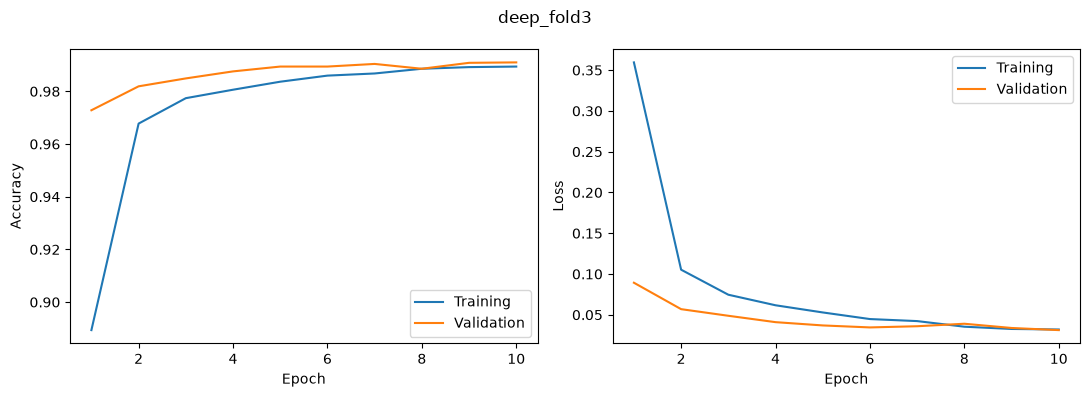

Epoch 1/10
240/240 - 6s - 25ms/step - accuracy: 0.8885 - loss: 0.3610 - val_accuracy: 0.9710 - val_loss: 0.0930
Epoch 2/10
240/240 - 2s - 7ms/step - accuracy: 0.9699 - loss: 0.1008 - val_accuracy: 0.9808 - val_loss: 0.0591
Epoch 3/10
240/240 - 2s - 7ms/step - accuracy: 0.9769 - loss: 0.0749 - val_accuracy: 0.9843 - val_loss: 0.0502
Epoch 4/10
240/240 - 2s - 7ms/step - accuracy: 0.9815 - loss: 0.0591 - val_accuracy: 0.9861 - val_loss: 0.0409
Epoch 5/10
240/240 - 2s - 7ms/step - accuracy: 0.9840 - loss: 0.0509 - val_accuracy: 0.9883 - val_loss: 0.0359
Epoch 6/10
240/240 - 2s - 7ms/step - accuracy: 0.9850 - loss: 0.0473 - val_accuracy: 0.9883 - val_loss: 0.0350
Epoch 7/10
240/240 - 2s - 7ms/step - accuracy: 0.9873 - loss: 0.0417 - val_accuracy: 0.9887 - val_loss: 0.0339
Epoch 8/10
240/240 - 2s - 7ms/step - accuracy: 0.9890 - loss: 0.0360 - val_accuracy: 0.9902 - val_loss: 0.0324
Epoch 9/10
240/240 - 2s - 7ms/step - accuracy: 0.9899 - loss: 0.0323 - val_accuracy: 0.9899 - val_loss: 0.0339


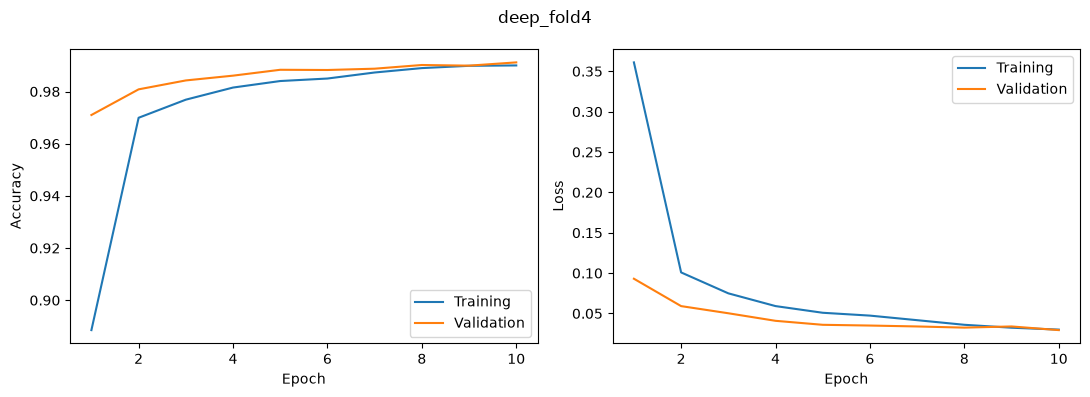

Epoch 1/10
240/240 - 6s - 24ms/step - accuracy: 0.8926 - loss: 0.3449 - val_accuracy: 0.9709 - val_loss: 0.0985
Epoch 2/10
240/240 - 2s - 7ms/step - accuracy: 0.9707 - loss: 0.0974 - val_accuracy: 0.9799 - val_loss: 0.0691
Epoch 3/10
240/240 - 2s - 7ms/step - accuracy: 0.9779 - loss: 0.0720 - val_accuracy: 0.9837 - val_loss: 0.0537
Epoch 4/10
240/240 - 2s - 7ms/step - accuracy: 0.9818 - loss: 0.0574 - val_accuracy: 0.9852 - val_loss: 0.0469
Epoch 5/10
240/240 - 2s - 7ms/step - accuracy: 0.9841 - loss: 0.0492 - val_accuracy: 0.9873 - val_loss: 0.0413
Epoch 6/10
240/240 - 2s - 7ms/step - accuracy: 0.9870 - loss: 0.0414 - val_accuracy: 0.9862 - val_loss: 0.0441
Epoch 7/10
240/240 - 2s - 8ms/step - accuracy: 0.9882 - loss: 0.0366 - val_accuracy: 0.9893 - val_loss: 0.0376
Epoch 8/10
240/240 - 2s - 9ms/step - accuracy: 0.9893 - loss: 0.0322 - val_accuracy: 0.9886 - val_loss: 0.0394
Epoch 9/10
240/240 - 2s - 9ms/step - accuracy: 0.9896 - loss: 0.0314 - val_accuracy: 0.9893 - val_loss: 0.0375


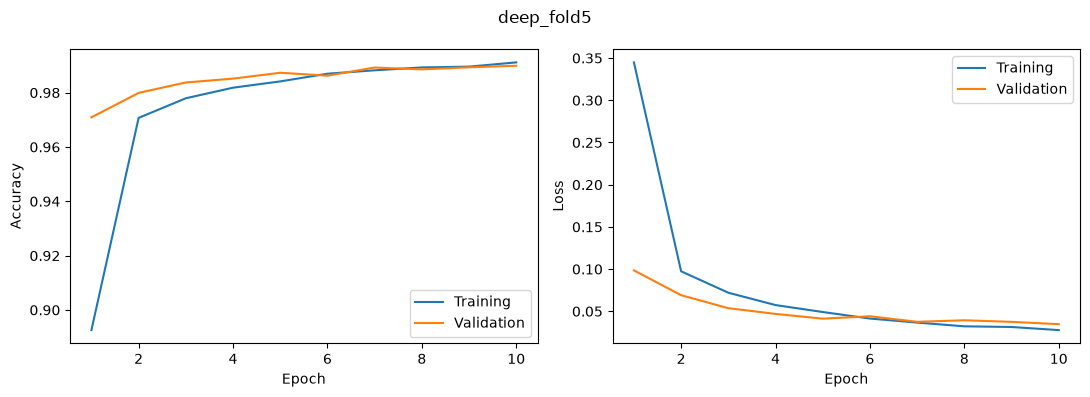

Epoch 1/10
240/240 - 9s - 39ms/step - accuracy: 0.9060 - loss: 0.2940 - val_accuracy: 0.9812 - val_loss: 0.0652
Epoch 2/10
240/240 - 4s - 16ms/step - accuracy: 0.9758 - loss: 0.0792 - val_accuracy: 0.9868 - val_loss: 0.0454
Epoch 3/10
240/240 - 4s - 16ms/step - accuracy: 0.9831 - loss: 0.0552 - val_accuracy: 0.9898 - val_loss: 0.0351
Epoch 4/10
240/240 - 4s - 16ms/step - accuracy: 0.9866 - loss: 0.0444 - val_accuracy: 0.9908 - val_loss: 0.0333
Epoch 5/10
240/240 - 4s - 16ms/step - accuracy: 0.9891 - loss: 0.0359 - val_accuracy: 0.9901 - val_loss: 0.0346
Epoch 6/10
240/240 - 4s - 16ms/step - accuracy: 0.9898 - loss: 0.0311 - val_accuracy: 0.9907 - val_loss: 0.0334
Epoch 7/10
240/240 - 4s - 16ms/step - accuracy: 0.9915 - loss: 0.0262 - val_accuracy: 0.9917 - val_loss: 0.0296
Epoch 8/10
240/240 - 4s - 16ms/step - accuracy: 0.9917 - loss: 0.0256 - val_accuracy: 0.9908 - val_loss: 0.0337
Epoch 9/10
240/240 - 4s - 16ms/step - accuracy: 0.9926 - loss: 0.0231 - val_accuracy: 0.9912 - val_loss:

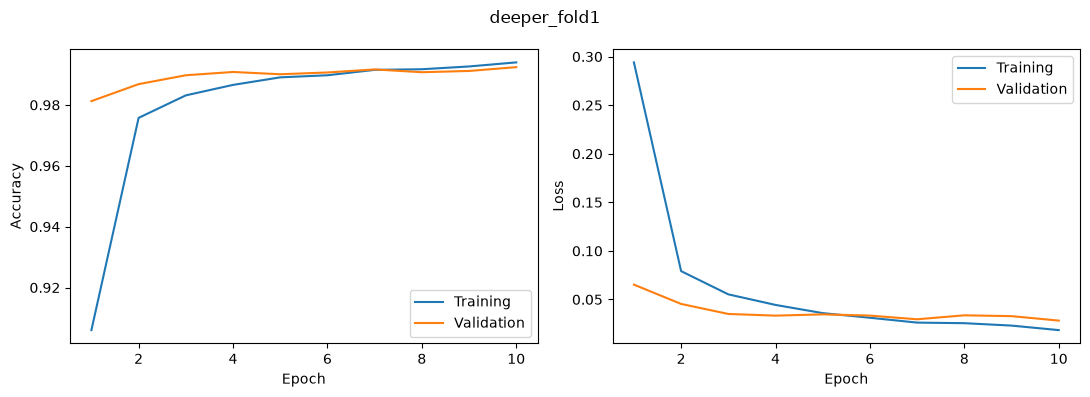

Epoch 1/10
240/240 - 9s - 39ms/step - accuracy: 0.9049 - loss: 0.3048 - val_accuracy: 0.9772 - val_loss: 0.0748
Epoch 2/10
240/240 - 4s - 16ms/step - accuracy: 0.9751 - loss: 0.0826 - val_accuracy: 0.9848 - val_loss: 0.0487
Epoch 3/10
240/240 - 4s - 16ms/step - accuracy: 0.9822 - loss: 0.0570 - val_accuracy: 0.9871 - val_loss: 0.0434
Epoch 4/10
240/240 - 4s - 16ms/step - accuracy: 0.9850 - loss: 0.0473 - val_accuracy: 0.9911 - val_loss: 0.0306
Epoch 5/10
240/240 - 4s - 16ms/step - accuracy: 0.9882 - loss: 0.0384 - val_accuracy: 0.9925 - val_loss: 0.0293
Epoch 6/10
240/240 - 4s - 16ms/step - accuracy: 0.9901 - loss: 0.0306 - val_accuracy: 0.9923 - val_loss: 0.0289
Epoch 7/10
240/240 - 4s - 16ms/step - accuracy: 0.9910 - loss: 0.0275 - val_accuracy: 0.9914 - val_loss: 0.0326
Epoch 8/10
240/240 - 4s - 16ms/step - accuracy: 0.9922 - loss: 0.0244 - val_accuracy: 0.9920 - val_loss: 0.0316
Epoch 9/10
240/240 - 4s - 16ms/step - accuracy: 0.9925 - loss: 0.0225 - val_accuracy: 0.9927 - val_loss:

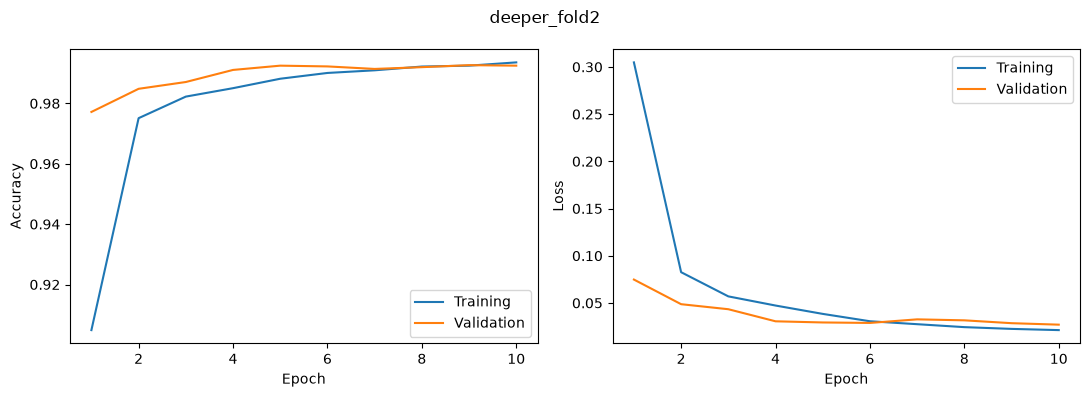

Epoch 1/10
240/240 - 9s - 36ms/step - accuracy: 0.9066 - loss: 0.2962 - val_accuracy: 0.9772 - val_loss: 0.0736
Epoch 2/10
240/240 - 4s - 16ms/step - accuracy: 0.9747 - loss: 0.0796 - val_accuracy: 0.9843 - val_loss: 0.0523
Epoch 3/10
240/240 - 4s - 16ms/step - accuracy: 0.9824 - loss: 0.0570 - val_accuracy: 0.9868 - val_loss: 0.0470
Epoch 4/10
240/240 - 4s - 16ms/step - accuracy: 0.9858 - loss: 0.0449 - val_accuracy: 0.9895 - val_loss: 0.0398
Epoch 5/10
240/240 - 4s - 16ms/step - accuracy: 0.9882 - loss: 0.0373 - val_accuracy: 0.9888 - val_loss: 0.0395
Epoch 6/10
240/240 - 4s - 16ms/step - accuracy: 0.9899 - loss: 0.0320 - val_accuracy: 0.9892 - val_loss: 0.0365
Epoch 7/10
240/240 - 4s - 16ms/step - accuracy: 0.9915 - loss: 0.0275 - val_accuracy: 0.9901 - val_loss: 0.0343
Epoch 8/10
240/240 - 4s - 16ms/step - accuracy: 0.9923 - loss: 0.0246 - val_accuracy: 0.9911 - val_loss: 0.0301
Epoch 9/10
240/240 - 4s - 16ms/step - accuracy: 0.9926 - loss: 0.0226 - val_accuracy: 0.9913 - val_loss:

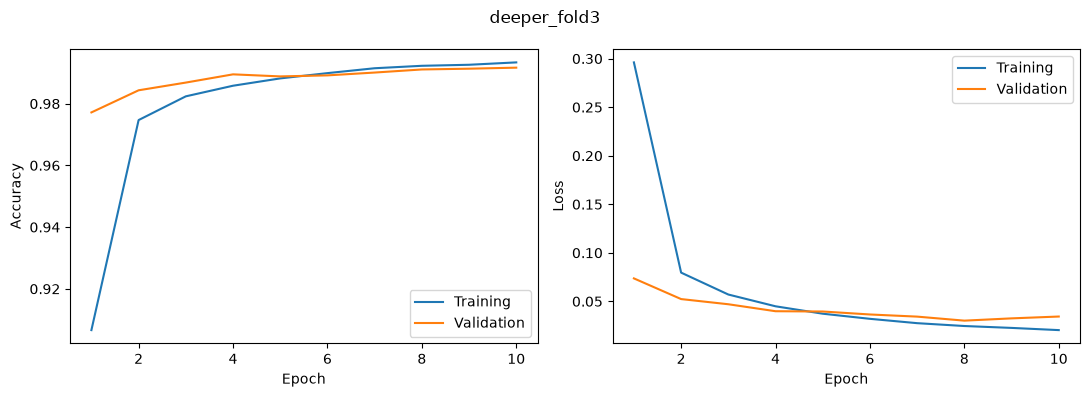

Epoch 1/10
240/240 - 8s - 35ms/step - accuracy: 0.9012 - loss: 0.3097 - val_accuracy: 0.9792 - val_loss: 0.0673
Epoch 2/10
240/240 - 4s - 16ms/step - accuracy: 0.9759 - loss: 0.0800 - val_accuracy: 0.9853 - val_loss: 0.0491
Epoch 3/10
240/240 - 4s - 16ms/step - accuracy: 0.9821 - loss: 0.0591 - val_accuracy: 0.9883 - val_loss: 0.0392
Epoch 4/10
240/240 - 4s - 16ms/step - accuracy: 0.9869 - loss: 0.0434 - val_accuracy: 0.9875 - val_loss: 0.0393
Epoch 5/10
240/240 - 4s - 16ms/step - accuracy: 0.9884 - loss: 0.0377 - val_accuracy: 0.9898 - val_loss: 0.0360
Epoch 6/10
240/240 - 4s - 16ms/step - accuracy: 0.9898 - loss: 0.0334 - val_accuracy: 0.9910 - val_loss: 0.0281
Epoch 7/10
240/240 - 4s - 16ms/step - accuracy: 0.9911 - loss: 0.0283 - val_accuracy: 0.9898 - val_loss: 0.0342
Epoch 8/10
240/240 - 4s - 16ms/step - accuracy: 0.9920 - loss: 0.0253 - val_accuracy: 0.9915 - val_loss: 0.0286
Epoch 9/10
240/240 - 4s - 16ms/step - accuracy: 0.9932 - loss: 0.0219 - val_accuracy: 0.9912 - val_loss:

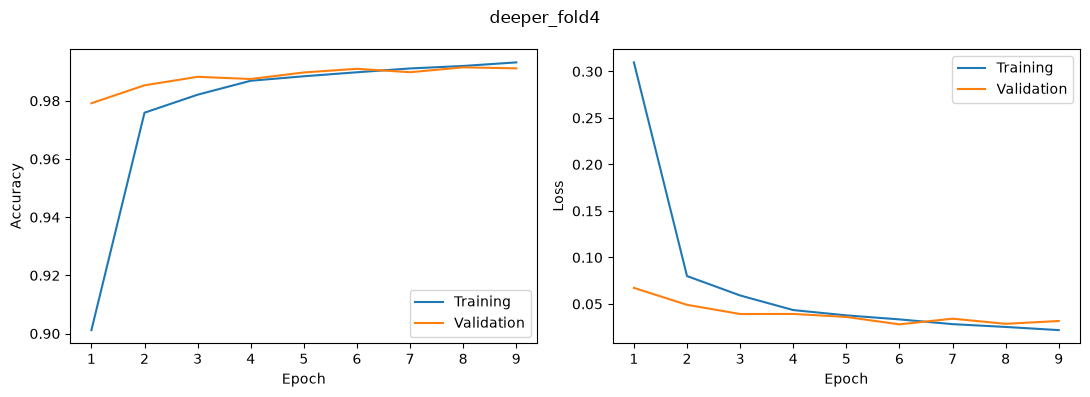

Epoch 1/10
240/240 - 8s - 35ms/step - accuracy: 0.9011 - loss: 0.3084 - val_accuracy: 0.9751 - val_loss: 0.0831
Epoch 2/10
240/240 - 4s - 16ms/step - accuracy: 0.9746 - loss: 0.0829 - val_accuracy: 0.9842 - val_loss: 0.0545
Epoch 3/10
240/240 - 4s - 16ms/step - accuracy: 0.9816 - loss: 0.0589 - val_accuracy: 0.9853 - val_loss: 0.0485
Epoch 4/10
240/240 - 4s - 16ms/step - accuracy: 0.9853 - loss: 0.0467 - val_accuracy: 0.9888 - val_loss: 0.0395
Epoch 5/10
240/240 - 4s - 16ms/step - accuracy: 0.9885 - loss: 0.0369 - val_accuracy: 0.9879 - val_loss: 0.0429
Epoch 6/10
240/240 - 4s - 16ms/step - accuracy: 0.9891 - loss: 0.0345 - val_accuracy: 0.9886 - val_loss: 0.0390
Epoch 7/10
240/240 - 4s - 16ms/step - accuracy: 0.9906 - loss: 0.0285 - val_accuracy: 0.9896 - val_loss: 0.0368
Epoch 8/10
240/240 - 4s - 16ms/step - accuracy: 0.9918 - loss: 0.0255 - val_accuracy: 0.9903 - val_loss: 0.0387
Epoch 9/10
240/240 - 4s - 16ms/step - accuracy: 0.9931 - loss: 0.0226 - val_accuracy: 0.9902 - val_loss:

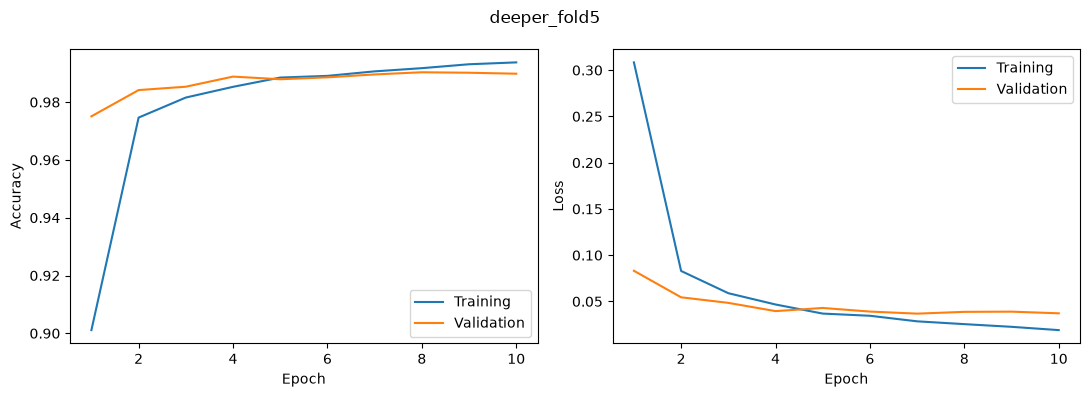

In [12]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []
for name in ['deep', 'deeper']:
    for fold, (fit_idx, holdout_idx) in enumerate(kfold.split(x_train, y_train), start=1):
        keras.backend.clear_session()
        keras.utils.set_random_seed(42 + fold)
        model = build_model(name)
        hist = model.fit(
            x_train[fit_idx], y_train_cat[fit_idx],
            validation_data=(x_train[holdout_idx], y_train_cat[holdout_idx]),
            epochs=10, batch_size=200, verbose=2,
            callbacks=[
                keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
                keras.callbacks.CSVLogger(f'results/{name}_fold{fold}_history.csv')
            ]
        )
        loss, accuracy = model.evaluate(x_train[holdout_idx], y_train_cat[holdout_idx], verbose=0)
        fold_results.append({
            'name': name,
            'fold': fold,
            'loss': loss,
            'accuracy': accuracy,
            'epochs': len(hist.epoch),
            'best_epoch': int(np.argmin(hist.history['val_loss']) + 1)
        })
        plot_history(hist.history, f'{name}_fold{fold}')

In [13]:
fold_results = pd.DataFrame(fold_results)
display(fold_results)

,name,fold,loss,accuracy,epochs,best_epoch
0,deep,1,0.034347,0.989583,10,10
1,deep,2,0.030506,0.991333,10,9
2,deep,3,0.031208,0.991000,10,10
3,deep,4,0.029368,0.991167,10,10
4,deep,5,0.034788,0.989917,10,10
5,deeper,1,0.028219,0.992417,10,10
6,deeper,2,0.027020,0.992500,10,10
7,deeper,3,0.030118,0.991083,10,8
8,deeper,4,0.028060,0.991000,9,6
9,deeper,5,0.036802,0.989583,10,7


In [14]:
cv_results = fold_results.groupby('name').agg(
    mean_accuracy=('accuracy', 'mean'),
    std_accuracy=('accuracy', 'std'),
    mean_loss=('loss', 'mean')
)
cv_results

,mean_accuracy,std_accuracy,mean_loss
name,,,
deep,0.990600,0.000794,0.032044
deeper,0.991317,0.001201,0.030044


# Final model

Choose by mean validation accuracy. Use the median best epoch count to train on all 60,000 training images.

In [15]:
best_name = cv_results['mean_accuracy'].idxmax()
best_folds = fold_results[fold_results['name'] == best_name]
final_epochs = int(np.median(best_folds['best_epoch']))
print('Best model:', best_name)
print('Epochs:', final_epochs)

Best model: deeper
Epochs: 8


In [16]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)
model = build_model(best_name)
hist = model.fit(x_train, y_train_cat, epochs=final_epochs, batch_size=200, verbose=2)

Epoch 1/8
300/300 - 8s - 28ms/step - accuracy: 0.9191 - loss: 0.2585
Epoch 2/8
300/300 - 4s - 15ms/step - accuracy: 0.9790 - loss: 0.0702
Epoch 3/8
300/300 - 4s - 15ms/step - accuracy: 0.9847 - loss: 0.0496
Epoch 4/8
300/300 - 4s - 15ms/step - accuracy: 0.9879 - loss: 0.0396
Epoch 5/8
300/300 - 4s - 15ms/step - accuracy: 0.9895 - loss: 0.0324
Epoch 6/8
300/300 - 4s - 15ms/step - accuracy: 0.9907 - loss: 0.0285
Epoch 7/8
300/300 - 4s - 15ms/step - accuracy: 0.9916 - loss: 0.0258
Epoch 8/8
300/300 - 4s - 15ms/step - accuracy: 0.9925 - loss: 0.0225


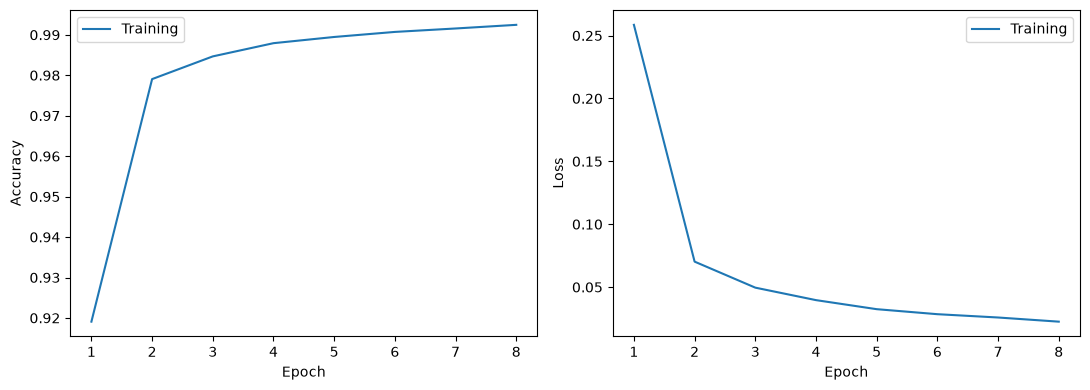

In [17]:
history = pd.DataFrame(hist.history)
epochs = np.arange(1, len(history) + 1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ['accuracy', 'loss']):
    ax.plot(epochs, history[metric], label='Training')
    if f'val_{metric}' in history:
        ax.plot(epochs, history[f'val_{metric}'], label='Validation')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

# Saving

In [18]:
model.save('models/lab5_best.keras')
loaded_model = keras.models.load_model('models/lab5_best.keras')
predictions = model.predict(x_test[:10], verbose=0)
loaded_predictions = loaded_model.predict(x_test[:10], verbose=0)
np.testing.assert_allclose(predictions, loaded_predictions, atol=1e-6)

# Results

In [19]:
loss, accuracy = loaded_model.evaluate(x_test, y_test_cat, verbose=0)
result = {
    'name': best_name,
    'epochs': final_epochs,
    'cv_accuracy': float(cv_results.loc[best_name, 'mean_accuracy']),
    'cv_std': float(cv_results.loc[best_name, 'std_accuracy']),
    'test_loss': loss,
    'test_accuracy': accuracy
}
pd.DataFrame([result])

,name,epochs,cv_accuracy,cv_std,test_loss,test_accuracy
0,deeper,8,0.991317,0.001201,0.021198,0.9939


In [20]:
for i, row in results.iterrows():
    candidate = keras.models.load_model(f"models/{row['name']}.keras")
    loss, accuracy = candidate.evaluate(x_test, y_test_cat, verbose=0)
    results.loc[i, 'test_loss'] = loss
    results.loc[i, 'test_accuracy'] = accuracy
display(results)

,name,parameters,train_loss,train_accuracy,val_loss,val_accuracy,best_epoch,test_loss,test_accuracy
0,simple,592074,0.009267,0.997611,0.051892,0.986000,8,0.035140,0.9890
1,complex,59933,0.018146,0.994370,0.040701,0.989500,8,0.027345,0.9900
2,deep,421642,0.008682,0.997648,0.036496,0.990667,10,0.023269,0.9926
3,deeper,467818,0.009649,0.997111,0.032255,0.990000,7,0.020089,0.9928


# Summary

Порівняно дві задані мережі та дві глибші на однаковому валідаційному поділі. Для кожної збережено ваги з найменшими валідаційними втратами.

| Model | Validation | Test | Parameters |
|---|---:|---:|---:|
| simple | 98.62% | 98.84% | 592,074 |
| complex | 98.82% | 99.18% | 59,933 |
| deep | 98.95% | 99.10% | 421,642 |
| deeper | 99.20% | 99.30% | 467,818 |

Для `deep` і `deeper` виконано п'ятикратну перехресну перевірку, щоразу з новими вагами. За середньою валідаційною точністю обрано **deeper**: **99.20%**, стандартне відхилення між частинами - 0.18 відсоткового пункту. Для обмеження перенавчання використано Dropout і ранню зупинку за валідаційними втратами.

Остаточну модель навчено на всіх 60 000 навчальних зображеннях протягом **10 епох**, за медіаною найкращих епох перехресної перевірки. Після збереження та завантаження точність на 10 000 тестових зображеннях становила **99.33%**, втрати - 0.0202. Тестові дані не використовувалися для вибору моделі або кількості епох.